# img2seq

In [ ]:
# !pip install captcha

In [4]:
import string
import numpy as np
from tqdm import tqdm
import os
import matplotlib.pyplot as plt
from tensorflow.keras import layers
import tensorflow as tf
from IPython.display import Image, display
from captcha.image import ImageCaptcha

In [5]:
chars = set()
#chars.update(string.ascii_lowercase)
#chars.update(string.ascii_uppercase)
chars.update({str(i) for i in range(10)})
chars = sorted(chars)
print('Number of chars: {0}, chars: {1}'.format(len(chars), chars))

Number of chars: 10, chars: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [6]:
img_dir = './captcha/'
if not os.path.exists(img_dir):
    os.makedirs(img_dir)

In [8]:
from captcha.image import ImageCaptcha
import uuid
create_dataset = True
captcha_len = 3
width = 40 + 20 * captcha_len
height = 100
n_images = 40000
if create_dataset:
    image = ImageCaptcha(width = width, height = height)
    print('Sample captcha str', np.random.choice(chars, captcha_len))
    seen = set()
    for _ in tqdm(range(n_images)):
        combi = np.random.choice(chars, captcha_len)
        captcha = ''.join(combi)
        image.write(captcha, '{0}{1}_{2}.png'.format(img_dir, captcha, uuid.uuid4()))

Sample captcha str ['0' '1' '7']


100%|██████████| 40000/40000 [02:17<00:00, 291.18it/s]


In [9]:
print('Number of captchas', len(os.listdir(img_dir)))
print('Some captchas', os.listdir(img_dir)[:5])

Number of captchas 46381
Some captchas ['527_b71bc9fc-959c-4700-8c03-4b232d40601f.png', '871_99bf5a62-c3db-4313-8b70-ea9a6c33fe16.png', '561_1b9bea3c-c2dc-4e64-9fd2-d4b2604929ba.png', '979_ade9aa42-4c21-4a76-87b5-2063da0eda2b.png', '022_7d116dd2-d91c-4631-b430-300e0bbddfc8.png']


image shape:  (100, 100, 3)


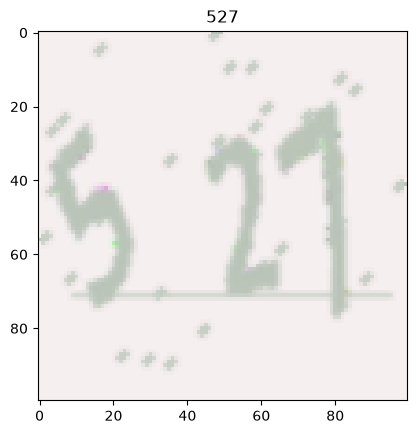

In [10]:
## Plot first sample
name = os.listdir(img_dir)[0]
x = tf.keras.preprocessing.image.load_img(os.path.join(img_dir, name))
x = tf.keras.preprocessing.image.img_to_array(x).astype(np.uint8)
print('image shape: ', x.shape)
plt.imshow(x)
plt.title(name.split('_')[0])
plt.show()

Number of images found:  46381
Number of labels found:  46381
Number of unique characters:  10
Characters present:  ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


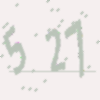

captcha: 527


In [ ]:
data_dir = img_dir
# Get list of all the images
images, labels = zip(*[(os.path.join(img_dir, name), name.split('_')[0])
                       for name in os.listdir(img_dir)])
images, labels = (np.array(list(images)), np.array(list(labels)))
characters = sorted(set(char for label in labels for char in label))

print("Number of images found: ", len(images))
print("Number of labels found: ", len(labels))
print("Number of unique characters: ", len(characters))
print("Characters present: ", characters)
display(Image(images[0]))
print('captcha:', labels[0])

## preprodcesamineto de datos

In [ ]:
# Mapping characters to integers
char_to_num = layers.StringLookup( # para hacer codificacion ohe de los datos
    vocabulary=list(characters), num_oov_indices=0, mask_token=None
)

# Mapping integers back to original characters
num_to_char = layers.StringLookup(
    vocabulary=char_to_num.get_vocabulary(), num_oov_indices=0,
    mask_token=None, invert=True
)


train_samples = int(0.7 * len(images))
val_split = int(0.8 * len(images))
x_train, y_train = images[:train_samples], labels[:train_samples]
x_val, y_val = images[train_samples:val_split], labels[train_samples:val_split]
x_test, y_test = images[val_split:], labels[val_split:]
print('x_train, y_train shape: ', x_train.shape, y_train.shape)

def encode_single_sample(img_path, label):
    
    img = tf.io.read_file(img_path)
    img = tf.io.decode_png(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    label = char_to_num(tf.strings.unicode_split(label, input_encoding="UTF-8"))
    # 7. Return a dict as our model is expecting two inputs
    zeros = tf.zeros((captcha_len,1))
    return ((img, zeros), label)


x_train, y_train shape:  (32466,) (32466,)


I0000 00:00:1794223139.856576   60539 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4597 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:01:00.0, compute capability: 7.5


In [14]:
batch_size = 128
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = tf.data.Dataset.from_tensor_slices((x_train, y_train)).map(encode_single_sample)
train_dataset = train_dataset.batch(batch_size).cache().shuffle(50).prefetch(buffer_size=AUTOTUNE)
    
validation_dataset = tf.data.Dataset.from_tensor_slices((x_val, y_val)).map(encode_single_sample)
validation_dataset = validation_dataset.batch(batch_size).cache().prefetch(buffer_size=AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((x_test, y_test)).map(encode_single_sample)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE).batch(batch_size)

W0000 00:00:1794223159.258302   61632 cache_dataset_ops.cc:956] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`, or if downstream operations drop elements (e.g. `batch(drop_remainder=True)`). You should use `dataset.take(k).cache().repeat()` instead, or ensure the dataset size is a multiple of the batch size before caching. Another common workaround is to place the `.cache()` operation after the operation that drops elements (like `.batch(...)`), if caching the transformed data is acceptable.


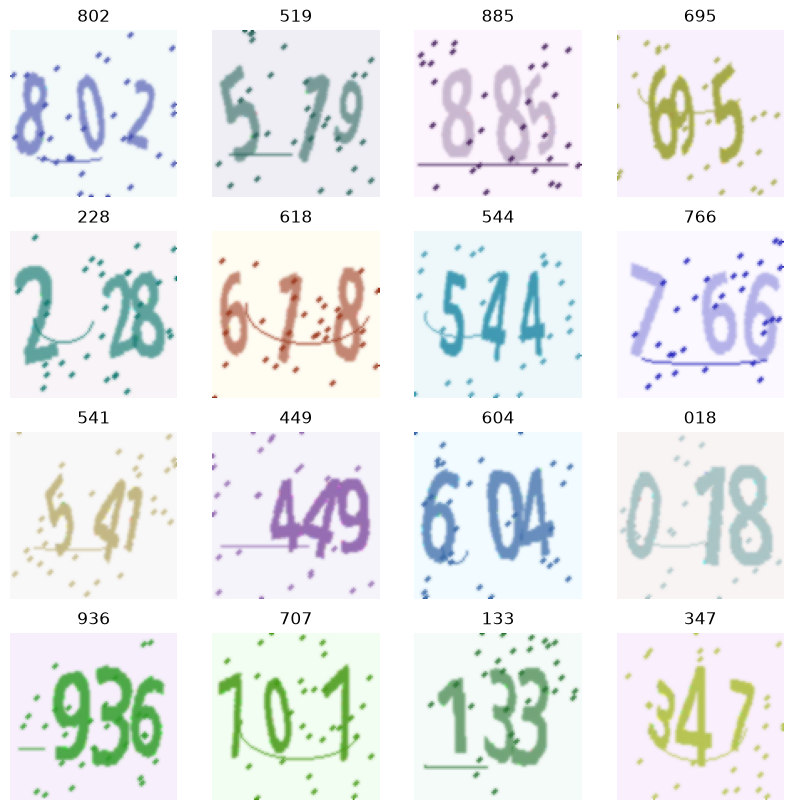

In [15]:
# plot samples
_, ax = plt.subplots(4, 4, figsize=(10, 10))
for (images_batch, zeros_batch), labels_batch in train_dataset.take(1):
    for i in range(16):
        img = (images_batch[i] * 255).numpy().astype("uint8")
        label = tf.strings.reduce_join(num_to_char(labels_batch[i])).numpy().decode("utf-8")
        ax[i // 4, i % 4].imshow(img, cmap="gray")
        ax[i // 4, i % 4].set_title(label)
        ax[i // 4, i % 4].axis("off")
plt.show()